# Chapter 75: Institutional Persistence, Path Dependence, and Evolution

This notebook reruns four worked examples from the chapter: search and selection among workshop routines, legitimacy as a substitute for enforcement, the horizon that locks in an old court system, and the threshold at which a broken allocation rule sparks collective action. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def expected_value(outcomes, probs):
    """Probability-weighted mean of outcomes. expected-utility-theorem: E[X] = 0.5(100) + 0.5(25) = 62.5."""
    if abs(sum(probs) - 1.0) > 1e-9:
        raise ValueError("probabilities must sum to one")
    return float(sum(p * x for p, x in zip(probs, outcomes)))


def annuity_factor(r, n):
    """Present value of 1 per period for n periods: (1 - (1 + r)^-n) / r (n when r = 0)."""
    return float(n) if r == 0 else (1.0 - (1.0 + r) ** (-n)) / r


def annuity_pv(payment, r, n):
    """payment x annuity_factor(r, n)."""
    return payment * annuity_factor(r, n)


def weighted_mean_productivity(levels, weights):
    """Weighted mean productivity sum(w A) / sum(w) across workshops (weight 0 means exit).

    Principle: evolutionary-routines. Book (ch075): (9 x 9 + 3 x 13) / 12 = 10;
    (7 x 9 + 4 x 13 + 1 x 7) / 12 = 122/12 = 10.17; (7 x 9 + 8 x 13) / 15 = 167/15 = 11.13.
    """
    total_w = float(sum(weights))
    total = float(sum(a * w for a, w in zip(levels, weights)))
    return {"total": total, "weight": total_w, "mean": total / total_w}


def required_effort(target, base, slopeL, L, slopeE):
    """Enforcement effort e solving target = base + slopeL L + slopeE e (floored at 0).

    Principle: legitimacy-as-capital. Book (ch075): c = 0.42 + 0.025L + 0.06e, target 0.84:
    L 8 gives 0.22/0.06 = 3.67; L 2 gives 0.37/0.06 = 6.17; L 6 gives 4.5.
    """
    return max(0.0, (target - base - slopeL * L) / slopeE)


def threshold_mobilization(willing, threshold):
    """Coordinated action is feasible when the number willing to act exceeds the threshold.

    Principle: moral-economy. Book (ch075): 45 > 36 mobilizes; 22 and 25 do not.
    """
    return {"mobilize": willing > threshold, "margin": willing - threshold}


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(expected_value=expected_value, annuity_factor=annuity_factor, annuity_pv=annuity_pv)


growth = SimpleNamespace(weighted_mean_productivity=weighted_mean_productivity)


public = SimpleNamespace(required_effort=required_effort, threshold_mobilization=threshold_mobilization)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'evolutionary-routines': {'O': 9,
                           'N': 13,
                           'D': 7,
                           'workshops': 12,
                           'A0': 10,
                           'A1_total': 122,
                           'A1': 10.17,
                           'weight_N': 2,
                           'A2_total': 167,
                           'A2_weight': 15,
                           'A2': 11.13},
 'legitimacy-as-capital': {'base': 0.42,
                           'slopeL': 0.025,
                           'slopeE': 0.06,
                           'target': 0.84,
                           'cost_per_unit': 90000,
                           'L_A': 8,
                           'L_B': 2,
                           'L_R': 6,
                           'e_A': 3.67,
                           'e_B': 6.17,
                           'e_R': 4.5,
                           'cost_A': 330000,
                           'cost_B': 555000,
                           'cost_R': 405000,
                           'gap_AB': 225000,
                           'saving': 150000,
                           'reform': 180000,
                           'years': 3,
                           'net': 270000},
 'path-dependence-institutional-lock-in': {'filings': 18000,
                                           'user_A': 11,
                                           'user_B': 7,
                                           'admin_A': 90000,
                                           'admin_B': 55000,
                                           'gain': 107000,
                                           'r': 0.05,
                                           'F': 320000,
                                           'F_standard': 180000,
                                           'PV_3': 291388,
                                           'PV_4': 379417,
                                           'PV_2': 198957},
 'moral-economy': {'threshold': 36,
                   'willing': {'A': 22, 'B': 45, 'C': 25},
                   'breach_gain': 1200,
                   'disruption': 3200,
                   'p': 0.6,
                   'reputation': 500,
                   'defiance': 2420,
                   'concession': 900},
 'constructed': {'evolutionary-routines': {'weight_N': [1, 3]},
                 'legitimacy-as-capital': {'L': [4], 'target': [0.76, 0.92]},
                 'path-dependence-institutional-lock-in': {'T': [5], 'F': [250000]},
                 'moral-economy': {'p': [0.3, 0.9]}}}


STAGES = {"initial": "Initial", "search": "After search", "selection": "After selection"}


def routine_layout(step, w):
    """(routine, jobs, weight) per workshop at each stage; D has weight 0 after selection."""
    if step == "initial":
        return [("O", 9, 1)] * 9 + [("N", 13, 1)] * 3
    if step == "search":
        return [("O", 9, 1)] * 7 + [("N", 13, 1)] * 4 + [("D", 7, 1)]
    return [("O", 9, 1)] * 7 + [("N", 13, w)] * 4 + [("D", 7, 0)]


def routines_picture(step="selection", w=2):
    shops = routine_layout(step, w)
    res = growth.weighted_mean_productivity([s[1] for s in shops], [s[2] for s in shops])
    a0 = growth.weighted_mean_productivity([9] * 9 + [13] * 3, [1] * 12)["mean"]
    a1 = growth.weighted_mean_productivity([9] * 7 + [13] * 4 + [7], [1] * 12)["mean"]
    a2 = growth.weighted_mean_productivity([9] * 7 + [13] * 4 + [7], [1] * 7 + [w] * 4 + [0])["mean"]
    mean = res["mean"]
    cols = {"O": "navy", "N": "teal", "D": "terracotta"}
    fig, ax = new_figure()
    x = 0.0
    seen = set()
    for kind, jobs, wt in shops:
        width = wt if wt else 0.6
        kw = {"color": PALETTE[cols[kind]], "edgecolor": "white", "linewidth": 1.2}
        if not wt:
            kw = {"facecolor": "none", "edgecolor": PALETTE["terracotta"], "linestyle": "dotted", "linewidth": 1.6}
        lab = {"O": "routine O, 9 jobs", "N": "routine N, 13 jobs", "D": "defective D, 7 jobs"}[kind]
        ax.bar(x, jobs, width=width, align="edge", label=None if kind in seen else lab, **kw)
        seen.add(kind)
        if not wt:
            label(ax, x + 0.6, jobs, "D exits", col="terracotta", dx=3, dy=2, ha="left")
        x += width + 0.08
    hline(ax, mean, f"average {num(mean)}", col="gold", style="solid", x_frac=0.02, lw=2)
    ax.set_xlim(-0.3, x + 2.6)
    ax.set_ylim(0, 18)
    ax.legend(loc="upper center", ncol=3, frameon=False)
    ax.set_xticks([])
    ax.set_xlabel("Workshops, bar width = market weight")
    ax.set_ylabel("Jobs per worker-week")
    stage = STAGES[step]
    metrics = {"Stage": stage, "Weighted total": num(res["total"], 0), "Total weight": num(res["weight"], 0),
               "Average productivity": num(mean), "Change from initial 10": num(mean - a0)}
    if step == "initial":
        steps = ["Nine workshops at 9 and three at 13, equal shares",
                 "Total = 9 x 9 + 3 x 13 = 81 + 39 = 120",
                 "Average = 120 / 12 = 10.00"]
        interp = (f"Before any search, the average is (9 x 9 + 3 x 13) / 12 = 120 / 12 = {num(mean)}. "
                  f"The expansion weight of {w} on N workshops applies only at the selection stage.")
    elif step == "search":
        steps = ["Two O workshops search: one copies N, one creates defective D at 7",
                 "Total = 7 x 9 + 4 x 13 + 1 x 7 = 63 + 52 + 7 = 122",
                 f"Average = 122 / 12 = {num(mean, 4)}, about {num(mean)}"]
        interp = (f"Search moves the unweighted average from 10 to 122 / 12 = {num(mean)}, a gain of about "
                  f"{num(a1 - a0)}, and it also creates a failed variant at 7 jobs. The expansion weight of {w} on "
                  f"N workshops applies only at the selection stage.")
    else:
        nt = 4 * 13 * w
        steps = [f"Weights: O 1 each, N {w} each, D exits (weight 0)",
                 f"Weighted total = 7 x 9 + 4 x {w} x 13 = 63 + {nt} = {num(res['total'], 0)}",
                 f"Total weight = 7 + 4 x {w} = {num(res['weight'], 0)}",
                 f"Average = {num(res['total'], 0)} / {num(res['weight'], 0)} = {num(mean, 4)}, about {num(mean)}",
                 f"Search gain {num(a1, 4)} - 10 = {num(a1 - a0, 4)}; selection gain {num(a2, 4)} - {num(a1, 4)} "
                 f"= {num(a2 - a1, 4)}"]
        more = "most" if (a2 - a1) > (a1 - a0) else "less than half"
        interp = (f"With N workshops expanding at weight {w} and D exiting, the average is "
                  f"{num(res['total'], 0)} / {num(res['weight'], 0)} = {num(mean)}. Of the {num(a2 - a0, 4)} rise "
                  f"from 10, search supplies {num(a1 - a0, 4)} and selection {num(a2 - a1, 4)}, so {more} of the "
                  f"gain comes from {'exit alone (equal weights)' if w == 1 else 'reweighting and exit'} rather than from the new "
                  f"adopter.")
    alt = (f"Bars for each workshop at the stage {stage.lower()}, height equal to jobs per worker-week and width "
           f"equal to market weight. The average productivity line sits at {num(mean)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def legitimacy_picture(stock=2, target=0.84):
    L = stock
    b = BV["legitimacy-as-capital"]
    base, sl, se, unit = b["base"], b["slopeL"], b["slopeE"], b["cost_per_unit"]
    e = public.required_effort(target, base, sl, L, se)
    e_base = public.required_effort(target, base, sl, 2, se)
    gap = target - base - sl * L
    gap_base = target - base - sl * 2
    cost = e * unit
    cost_base = e_base * unit
    saving = cost_base - cost
    net3 = 3 * saving - b["reform"]
    fig, ax = new_figure()
    import numpy as np
    es = np.linspace(0, 9, 50)
    for lev, col in zip([2, 4, 6, 8], ["terracotta", "gold", "teal", "navy"]):
        sel = lev == L
        ax.plot(es, base + sl * lev + se * es, color=PALETTE[col], linewidth=2.6 if sel else 1.2,
                alpha=1 if sel else 0.55)
        y_end = base + sl * lev + se * 0.2
        label(ax, 0.2, y_end, f"L = {lev}", col=col, dx=0, dy=6, ha="left", va="bottom")
    hline(ax, target, f"required compliance {num(target)}", col="ink", x_frac=0.55)
    mark(ax, e, target, f"e = {num(e)}", col="ink", dx=8, dy=-8, ha="left", va="top")
    ax.set_xlim(0, 9)
    ax.set_ylim(0.4, 1.0)
    ax.set_xlabel("Enforcement effort e")
    ax.set_ylabel("Share of riders complying c")
    metrics = {"Required effort e": num(e), "Annual enforcement cost": money(cost, 0),
               "Effort at L = 2": num(e_base), "Annual saving vs L = 2": money(saving, 0),
               "Three-year saving minus $180,000 reform": money(net3, 0)}
    steps = [f"e = ({num(target)} - 0.42 - 0.025 x {L}) / 0.06 = {num(gap)} / 0.06 = {num(e, 4)}",
             f"Cost = {num(gap)} x 90,000 / 0.06 = {money(cost, 0)}",
             f"At L = 2: e = {num(gap_base)} / 0.06 = {num(e_base, 4)}, cost {money(cost_base, 0)}",
             f"Saving = {money(cost_base, 0)} - {money(cost, 0)} = {money(saving, 0)} per year",
             f"Three years: 3 x {money(saving, 0)} - $180,000 = {money(net3, 0)}"]
    if L == 2:
        verdict = ("At the baseline stock L = 2 there is no saving, so a $180,000 reform that left L at 2 would be "
                   "a pure loss of $180,000.")
    elif net3 > 0:
        verdict = (f"If a $180,000 reform lifted L from 2 to {L} for three years, it would save "
                   f"{money(saving, 0)} a year and come out {money(net3, 0)} ahead, ignoring discounting.")
    else:
        verdict = (f"If a $180,000 reform lifted L from 2 to {L} for three years, the saving of {money(saving, 0)} a "
                   f"year would not cover it: the three-year net is {money(net3, 0)}.")
    interp = (f"To reach {num(target)} compliance with L = {L}, effort must cover {num(target)} - 0.42 - "
              f"0.025 x {L} = {num(gap)}, so e = {num(gap)} / 0.06 = {num(e)} and the annual cost is "
              f"{money(cost, 0)}. {verdict}")
    alt = (f"Compliance rises linearly with enforcement effort, one line per legitimacy stock. The line for "
           f"L = {L} meets the required compliance {num(target)} at effort {num(e)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def lockin_picture(years=3, cost=320_000):
    T, F = years, cost
    b = BV["path-dependence-institutional-lock-in"]
    gain, r = b["gain"], b["r"]
    pvs = [choice.annuity_pv(gain, r, t) for t in range(1, T + 1)]
    pv = pvs[-1]
    factor = choice.annuity_factor(r, T)
    switch = pv > F
    fig, ax = new_figure()
    xs = list(range(1, T + 1))
    ax.bar(xs, pvs, width=0.6, color=[PALETTE["teal"] if v > F else PALETTE["navy"] for v in pvs])
    for x_, v in zip(xs, pvs):
        label(ax, x_, v, money(v, 0), col="ink", dx=0, dy=3, ha="center")
    hline(ax, F, None, col="terracotta", style="solid", lw=2)
    label(ax, 5.45, F, f"cost F\n{money(F, 0)}", col="terracotta", dx=0, dy=4, ha="left")
    ax.text(0.98, 0.97, "Switch to B" if switch else "Retain A", transform=ax.transAxes, ha="right", va="top",
            fontsize=12, color=PALETTE["teal" if switch else "terracotta"], fontweight="bold")
    ax.set_xlim(0.4, 6.5)
    ax.set_ylim(0, 560_000)
    ax.set_xticks(xs, [f"{t}" for t in xs])
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:,.0f}k")
    ax.set_xlabel("Decision horizon (years)")
    ax.set_ylabel("Present value of the annual gain ($)")
    metrics = {"Annual gain": money(gain, 0), "Annuity factor": num(factor, 6),
               f"PV over {T} years": money(pv, 0), "Conversion cost F": money(F, 0),
               "PV minus F": money(pv - F, 0), "Decision": "Switch to B" if switch else "Retain A"}
    steps = ["Gain = 18,000 x (11 - 7) + (90,000 - 55,000) = 72,000 + 35,000 = $107,000",
             f"Factor = (1 - 1.05^-{T}) / 0.05 = {num(factor, 6)}",
             f"PV = 107,000 x {num(factor, 6)} = {money(pv, 0)}",
             f"{money(pv, 0)} {'>' if switch else '<'} {money(F, 0)}: {'switch to B' if switch else 'retain A'}"]
    yrs = "year" if T == 1 else "years"
    interp = (f"Over {T} {yrs} at 5 percent, the $107,000 annual gain is worth 107,000 x {num(factor, 6)} = "
              f"{num(pv, 0)} dollars, which is {'above' if switch else 'below'} the {money(F, 0)} conversion cost, so a "
              f"decision maker with this horizon {'switches to B' if switch else 'rationally retains A'}. The "
              f"system is the same in every case; only the horizon and the cost of conversion change.")
    alt = (f"Bars show the present value of the annual gain over horizons of 1 to {T} years against a line at "
           f"the conversion cost {money(F, 0)}. At {T} years the value is {money(pv, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


SCEN = {"A": ("A procedure followed", "A"), "B": ("B secret diversion", "B"), "C": ("C announced clinic rule", "C")}


def moral_picture(scen="B", p=0.60):
    b = BV["moral-economy"]
    th = b["threshold"]
    willing = b["willing"][scen]
    mob = public.threshold_mobilization(willing, th)
    cost = choice.expected_value([b["disruption"], 0.0], [p, 1 - p]) + b["reputation"]
    conc = b["concession"]
    concede = conc < cost
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.bar([0], [willing], width=0.5, color=PALETTE["teal" if mob["mobilize"] else "navy"])
    ax1.annotate(f"{willing} willing", (0, willing), xytext=(0, 4), textcoords="offset points", ha="center",
                 va="bottom", fontsize=10.5, color=PALETTE["ink"])
    hline(ax1, th, f"threshold {th}", col="terracotta", style="solid", x_frac=0.62, lw=2)
    ax1.set_xlim(-0.6, 0.9)
    ax1.set_ylim(0, 60)
    ax1.set_xticks([0], [SCEN[scen][0]])
    ax1.set_ylabel("Residents willing to act")
    ax1.set_xlabel("Scenario")
    ax1.set_title("Mobilization" + (" occurs" if mob["mobilize"] else " does not occur"), fontsize=12)
    ax2.bar([0, 1], [cost, conc], width=0.55, color=[PALETTE["terracotta"], PALETTE["teal"]])
    for x_, v in zip([0, 1], [cost, conc]):
        ax2.annotate(money(v, 0), (x_, v), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                     fontsize=10.5, color=PALETTE["ink"])
    ax2.set_xticks([0, 1], ["expected defiance cost", "concession cost"])
    ax2.set_ylim(0, 4_000)
    ax2.set_ylabel("Merchant's cost ($)")
    ax2.set_xlabel("Merchant's option")
    ax2.set_title("Merchant's comparison if residents mobilize", fontsize=12)
    metrics = {"Willing to act": str(willing), "Threshold": str(th),
               "Mobilization": "yes" if mob["mobilize"] else "no",
               "Expected defiance cost": money(cost, 0), "Concession cost": money(conc, 0),
               "Merchant's response": ("concede" if concede else "defy") if mob["mobilize"] else "no demand to answer"}
    rel = ">" if willing > th else ("=" if willing == th else "<")
    steps = [f"Willing {willing} {rel} threshold {th}: {'mobilize' if mob['mobilize'] else 'no collective action'}",
             f"Expected defiance cost = {num(p)} x 3,200 + 500 = {num(p * 3200, 0)} + 500 = {money(cost, 0)}",
             f"Concession cost {money(conc, 0)} {'<' if concede else '>'} {money(cost, 0)}"]
    if mob["mobilize"]:
        resp = (f"Facing disruption with probability {num(p)}, the merchant's expected defiance cost is "
                f"{num(p)} x 3,200 + 500 = {num(cost, 0)} dollars, {'above' if concede else 'below'} the $900 cost of "
                f"returning the 18 sacks under supervision, so the merchant {'concedes' if concede else 'defies'}.")
    else:
        resp = (f"With no collective action there is no demand for the merchant to answer; the expected defiance "
                f"cost {num(p)} x 3,200 + 500 = {num(cost, 0)} dollars would matter only if residents mobilized.")
    interp = (f"In scenario {SCEN[scen][1]}, {willing} residents are willing to act against a threshold of {th}, so "
              f"coordinated action {'is feasible' if mob['mobilize'] else 'does not occur'}. {resp}")
    alt = (f"Left: {willing} residents willing to act against a threshold of {th}. Right: expected defiance cost "
           f"{money(cost, 0)} against a concession cost of $900.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Evolutionary routines: search, imitation, and selection

Twelve workshops: nine use routine O (9 jobs per worker-week) and three use N (13). Search turns one O workshop into N and another into a defective D (7). Selection gives N weight 2 and lets D exit.

$$\bar A_1=\frac{7(9)+4(13)+1(7)}{12}=\frac{122}{12}\approx10.17, \qquad \bar A_2=\frac{7(9)+8(13)}{15}=\frac{167}{15}\approx11.13$$

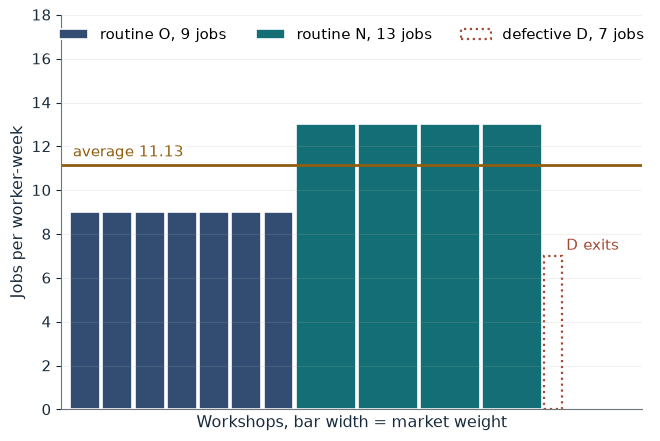

Stage                   After selection
Weighted total          167
Total weight            15
Average productivity    11.13
Change from initial 10  1.13

Worked steps:
  1. Weights: O 1 each, N 2 each, D exits (weight 0)
  2. Weighted total = 7 x 9 + 4 x 2 x 13 = 63 + 104 = 167
  3. Total weight = 7 + 4 x 2 = 15
  4. Average = 167 / 15 = 11.1333, about 11.13
  5. Search gain 10.1667 - 10 = 0.1667; selection gain 11.1333 - 10.1667 = 0.9667

With N workshops expanding at weight 2 and D exiting, the average is 167 / 15 = 11.13. Of the 1.1333 rise from 10, search supplies 0.1667 and selection 0.9667, so most of the gain comes from reweighting and exit rather than from the new adopter.


In [2]:
show(routines_picture(step='selection', w=2))

Change one input, `w`, and hold the others at the book's values:

In [3]:
sweep(routines_picture, 'w', [1, 2, 3], {'step': 'selection'}, ['Weighted total', 'Total weight', 'Average productivity'])

w | Weighted total | Total weight | Average productivity
1 | 115 | 11 | 10.45
2 | 167 | 15 | 11.13
3 | 219 | 19 | 11.53


Search lifts the average by only 0.1667; expansion of N and exit of D add 0.9667. With equal shares the average would stay at 10.17.

## 2. Legitimacy as political capital: the cost of compliance

Compliance follows $c=0.42+0.025L+0.06e$, each effort unit costs \$90,000 and 84 percent of riders must comply.

$$e_A=\frac{0.84-0.42-0.025(8)}{0.06}=\frac{0.22}{0.06}\approx3.67$$

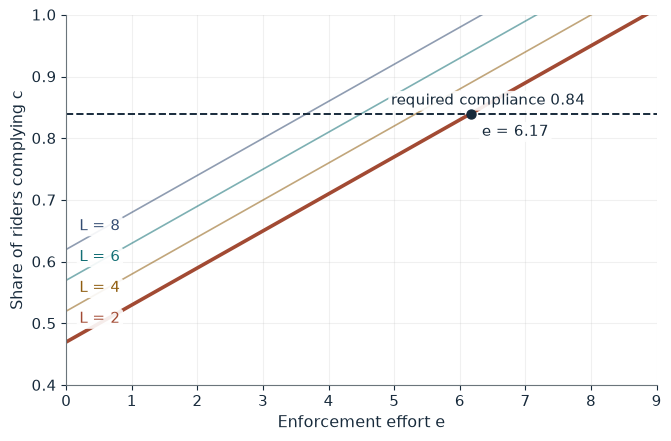

Required effort e                        6.17
Annual enforcement cost                  $555,000
Effort at L = 2                          6.17
Annual saving vs L = 2                   $0
Three-year saving minus $180,000 reform  -$180,000

Worked steps:
  1. e = (0.84 - 0.42 - 0.025 x 2) / 0.06 = 0.37 / 0.06 = 6.1667
  2. Cost = 0.37 x 90,000 / 0.06 = $555,000
  3. At L = 2: e = 0.37 / 0.06 = 6.1667, cost $555,000
  4. Saving = $555,000 - $555,000 = $0 per year
  5. Three years: 3 x $0 - $180,000 = -$180,000

To reach 0.84 compliance with L = 2, effort must cover 0.84 - 0.42 - 0.025 x 2 = 0.37, so e = 0.37 / 0.06 = 6.17 and the annual cost is $555,000. At the baseline stock L = 2 there is no saving, so a $180,000 reform that left L at 2 would be a pure loss of $180,000.


In [4]:
show(legitimacy_picture(stock=2, target=0.84))

Change one input, `stock`, and hold the others at the book's values:

In [5]:
sweep(legitimacy_picture, 'stock', [2, 4, 6, 8], {'target': 0.84}, ['Required effort e', 'Annual enforcement cost', 'Annual saving vs L = 2'])

stock | Required effort e | Annual enforcement cost | Annual saving vs L = 2
2 | 6.17 | $555,000 | $0
4 | 5.33 | $480,000 | $75,000
6 | 4.50 | $405,000 | $150,000
8 | 3.67 | $330,000 | $225,000


Raising L from 2 to 6 cuts the cost from \$555,000 to \$405,000, a saving of \$150,000 a year; over three years a \$180,000 reform nets 3 x \$150,000 - \$180,000 = \$270,000.

## 3. Path dependence and lock-in: horizon against conversion cost

System B saves \$107,000 a year; conversion costs \$320,000 and the discount rate is 5 percent.

$$PV_3=\$107{,}000\left(\frac{1-(1.05)^{-3}}{0.05}\right)\approx\$291{,}388$$

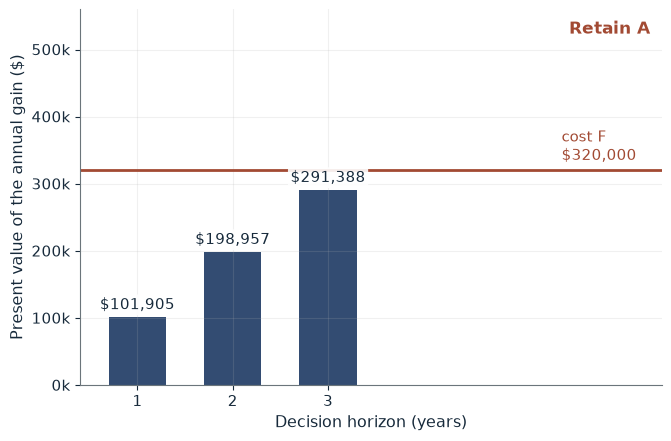

Annual gain        $107,000
Annuity factor     2.723248
PV over 3 years    $291,388
Conversion cost F  $320,000
PV minus F         -$28,612
Decision           Retain A

Worked steps:
  1. Gain = 18,000 x (11 - 7) + (90,000 - 55,000) = 72,000 + 35,000 = $107,000
  2. Factor = (1 - 1.05^-3) / 0.05 = 2.723248
  3. PV = 107,000 x 2.723248 = $291,388
  4. $291,388 < $320,000: retain A

Over 3 years at 5 percent, the $107,000 annual gain is worth 107,000 x 2.723248 = 291,388 dollars, which is below the $320,000 conversion cost, so a decision maker with this horizon rationally retains A. The system is the same in every case; only the horizon and the cost of conversion change.


In [6]:
show(lockin_picture(years=3, cost=320_000))

Change one input, `years`, and hold the others at the book's values:

In [7]:
sweep(lockin_picture, 'years', [2, 3, 4, 5], {'cost': 320000}, ['Annuity factor', 'Decision'])

years | Annuity factor | Decision
2 | 1.859410 | Retain A
3 | 2.723248 | Retain A
4 | 3.545951 | Switch to B
5 | 4.329477 | Switch to B


A three-year decision maker retains A because \$291,388 is below \$320,000; at four years the gain is worth \$379,417 and B wins. Cutting the cost to \$180,000 makes two years enough (`cost=180_000, years=2`).

## 4. Moral economy: the mobilization threshold

Residents act together only when more than 36 are willing. Secret diversion raises willingness to 45. The merchant's expected defiance cost is

$$0.60(\$3{,}200)+\$500=\$2{,}420$$

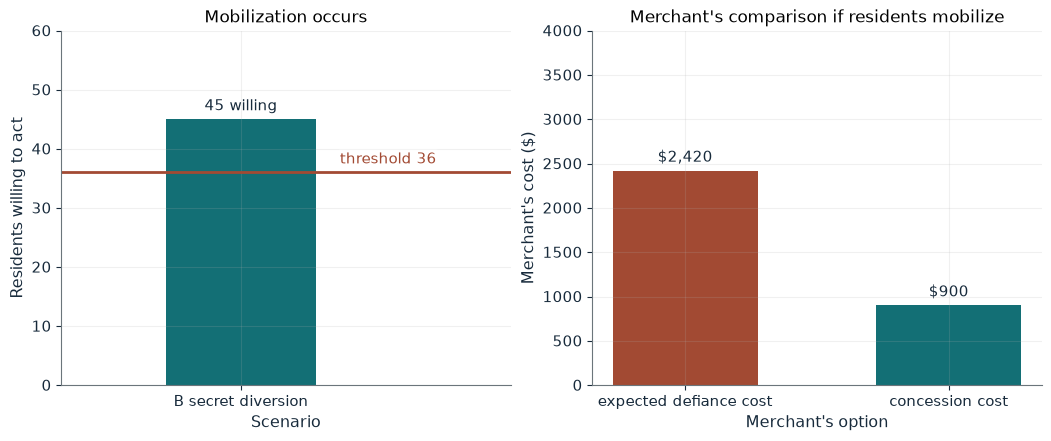

Willing to act          45
Threshold               36
Mobilization            yes
Expected defiance cost  $2,420
Concession cost         $900
Merchant's response     concede

Worked steps:
  1. Willing 45 > threshold 36: mobilize
  2. Expected defiance cost = 0.60 x 3,200 + 500 = 1,920 + 500 = $2,420
  3. Concession cost $900 < $2,420

In scenario B, 45 residents are willing to act against a threshold of 36, so coordinated action is feasible. Facing disruption with probability 0.60, the merchant's expected defiance cost is 0.60 x 3,200 + 500 = 2,420 dollars, above the $900 cost of returning the 18 sacks under supervision, so the merchant concedes.


In [8]:
show(moral_picture(scen='B', p=0.60))

Change one input, `scen`, and hold the others at the book's values:

In [9]:
sweep(moral_picture, 'scen', ['A', 'B', 'C'], {'p': 0.6}, ['Willing to act', 'Mobilization', "Merchant's response"])

scen | Willing to act | Mobilization | Merchant's response
A | 22 | no | no demand to answer
B | 45 | yes | concede
C | 25 | no | no demand to answer


Only the broken procedure in scenario B pushes willingness past the threshold. Facing \$2,420 of expected defiance cost, the merchant prefers the \$900 concession.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

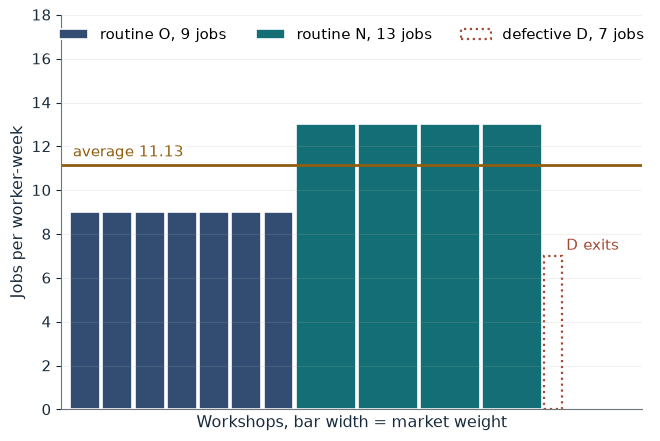

Stage                   After selection
Weighted total          167
Total weight            15
Average productivity    11.13
Change from initial 10  1.13

Worked steps:
  1. Weights: O 1 each, N 2 each, D exits (weight 0)
  2. Weighted total = 7 x 9 + 4 x 2 x 13 = 63 + 104 = 167
  3. Total weight = 7 + 4 x 2 = 15
  4. Average = 167 / 15 = 11.1333, about 11.13
  5. Search gain 10.1667 - 10 = 0.1667; selection gain 11.1333 - 10.1667 = 0.9667

With N workshops expanding at weight 2 and D exiting, the average is 167 / 15 = 11.13. Of the 1.1333 rise from 10, search supplies 0.1667 and selection 0.9667, so most of the gain comes from reweighting and exit rather than from the new adopter.


In [10]:
show(routines_picture(step='selection', w=2))

## Practice

**1.** If every workshop kept an equal share after search, what would average productivity be?

<details><summary>Answer</summary>

(7 x 9 + 4 x 13 + 1 x 7) / 12 = 122 / 12 = 10.17.

</details>

**2.** With a compatibility standard cutting conversion cost to \$180,000, is a two-year horizon enough to switch?

<details><summary>Answer</summary>

PV_2 = 107,000 x (1 - 1.05^-2) / 0.05 = 107,000 x 1.859410 = \$198,957, above \$180,000, so switch.

</details>

**3.** What is the merchant's expected defiance cost if disruption has probability 0.30?

<details><summary>Answer</summary>

0.30 x 3,200 + 500 = \$1,460, still above the \$900 concession cost (0.30 is a constructed value).

</details>